# Walkthrough: Discovering And Generating Features With `llm-feature-gen`

`llm-feature-gen` discovers interpretable features from unstructured data and generates a tabular dataset for downstream machine learning.

This notebook shows one complete **example workflow** using Banking77. For your own project, choose your **own dataset** and define your **own classification task**.

Links:
- PyPI: [https://pypi.org/project/llm-feature-gen/](https://pypi.org/project/llm-feature-gen/)
- GitHub: [https://github.com/JuliaYershova/llm-feature-gen](https://github.com/JuliaYershova/llm-feature-gen/)

If this library is useful, please give it a **star** ⭐ to show support. Fork the repository and, if you improve something, open an issue or pull request 🚀.

> This notebook is intentionally generic: it contains no assignment-specific requirements and no API credentials. If you received a separate setup/assignment document (e.g. as part of a course), follow that for exact submission requirements and provider credentials.

Install the released package from PyPI `llm-feature-gen`.

In [ ]:
# Install the package. If you're working from your own fork of the GitHub
# repository instead of the PyPI release, install your fork here instead.

%pip install -U -qq llm-feature-gen datasets scikit-learn matplotlib pandas

import sys
print(sys.executable)

import llm_feature_gen
llm_feature_gen.__file__

## Step 1: Example Dataset For The Walkthrough

This notebook uses the `mteb/banking77` dataset from Hugging Face only as a **worked example**. For your own assignment, you should choose your **own dataset** and define your **own machine-learning task**.

Because of its discovery prompts, the library assumes a **fixed two-class** workflow and will therefore only work with a subset of selected classes in this example.


In [ ]:
from pathlib import Path

import pandas as pd
from datasets import load_dataset

selected_classes = [
    'card_arrival', 
    'card_delivery_estimate'
]

# Data reduction to decrease computation time.
train_fraction = 0.3
test_fraction = 0.2
random_seed = 42

banking = load_dataset("mteb/banking77")

train_df = (banking["train"].to_pandas()[["text", "label_text"]]
            .rename(columns={"label_text": "class_name"})
            .query("class_name in @selected_classes")
            .groupby("class_name", group_keys=False)
            .sample(frac=train_fraction, random_state=random_seed)
            .reset_index(drop=True))


test_df = (banking["test"].to_pandas()[["text", "label_text"]]
           .rename(columns={"label_text": "class_name"})
           .query("class_name in @selected_classes")
           .groupby("class_name", group_keys=False)
           .sample(frac=test_fraction, random_state=random_seed)
           .reset_index(drop=True))

for frame in [train_df, test_df]:
    frame["text"] = frame["text"].fillna("").str.strip()

print(pd.concat([
    train_df.assign(split="train"),
    test_df.assign(split="test"),]).groupby(["split", "class_name"]).size())

## Step 2: Prepare The Folder Structure

The library expects one folder for discovery samples and one folder with one subfolder per class for generation.

For a cleaner evaluation, this notebook creates three folder groups:
- `discover_texts/` sampled only from the training split
- `train_texts/` with all selected training examples
- `test_texts/` with all selected test examples

In this notebook, discovery uses a random 10% sample from the training data for each selected class, while generation uses all available train and test examples for those classes.


In [ ]:
import shutil

project_dir = Path("walkthrough_data")
discover_dir = project_dir / "discover_texts"
train_texts_dir = project_dir / "train_texts"
test_texts_dir = project_dir / "test_texts"
output_dir = project_dir / "outputs"

discovery_fraction = 0.1

for path in [discover_dir, train_texts_dir, test_texts_dir, output_dir]:
    if path.exists():
        shutil.rmtree(path)
    path.mkdir(parents=True, exist_ok=True)

for class_name in selected_classes:
    (train_texts_dir / class_name).mkdir(parents=True, exist_ok=True)
    (test_texts_dir / class_name).mkdir(parents=True, exist_ok=True)

discovery_sizes = {}

for class_name in selected_classes:
    class_train_df = train_df[train_df["class_name"] == class_name].reset_index(drop=True)
    class_test_df = test_df[test_df["class_name"] == class_name].reset_index(drop=True)

    discovery_size = max(4, int(len(class_train_df) * discovery_fraction))
    discovery_sample = class_train_df.sample(n=min(discovery_size, len(class_train_df)), random_state=random_seed).reset_index(drop=True)
    discovery_sizes[class_name] = len(discovery_sample)

    for i, text in enumerate(discovery_sample["text"], start=1):
        (discover_dir / f"{class_name}_discover_{i}.txt").write_text(text, encoding="utf-8")

    for i, text in enumerate(class_train_df["text"], start=1):
        (train_texts_dir / class_name / f"{class_name}_train_{i}.txt").write_text(text, encoding="utf-8")

    for i, text in enumerate(class_test_df["text"], start=1):
        (test_texts_dir / class_name / f"{class_name}_test_{i}.txt").write_text(text, encoding="utf-8")

print("discovery files:", len(list(discover_dir.glob("*.txt"))))
for class_name in selected_classes:
    print(class_name)
    print(" - discovery:", discovery_sizes[class_name])
    print(" - train:", len(list((train_texts_dir / class_name).glob("*.txt"))))
    print(" - test:", len(list((test_texts_dir / class_name).glob("*.txt"))))


## Step 3: Discover And Generate

This is the core of the walkthrough: one `discover` call and one `generate` call. You may try a different model if you want; available server models can be listed with `provider.client.models.list()`.

This library is not restricted to paid commercial APIs. The pipeline architecture features a built-in `LocalProvider` which acts as an adapter allowing you to route all requests to any local server running an OpenAI-compatible interface (e.g. Ollama, vLLM, LM Studio), or to a hosted OpenAI-compatible endpoint.

Provider credentials are **not** hardcoded in this notebook. There are two ways to set them, in the "Provider setup" cell below:

1. **Environment variables** (or a `.env` file in this folder), if that's convenient in your environment: `LOCAL_OPENAI_BASE_URL`, `LOCAL_OPENAI_API_KEY`, `LOCAL_MODEL_TEXT`. Leave `base_url`/`api_key`/`text_model` empty (`""`) and `LocalProvider` picks the environment variables up automatically.
2. **Fill them in directly** as `base_url`/`api_key`/`text_model`. This is the simplest option on hosted notebook servers where creating a `.env` file is awkward.

If you were given a separate setup document (e.g. for a course), use the values from there. Otherwise, point them at any OpenAI-compatible server you have access to — a local Ollama server works out of the box with everything left empty.

⚠️ If you fill in your own credentials directly below, clear them back to `""` before sharing or submitting this notebook, so your key isn't included in what you hand in.

In [ ]:
# Provider setup
from llm_feature_gen.providers.local_provider import LocalProvider

# Fill these in directly, or leave empty ("") to use environment variables / a
# .env file instead (see the markdown cell above). Leaving everything empty
# also works if you're running a local Ollama server with its own defaults.
base_url = ""
api_key = ""
text_model = ""

if not (base_url or api_key or text_model):
    print(
        "No credentials filled in above. If you have LOCAL_OPENAI_BASE_URL / "
        "LOCAL_OPENAI_API_KEY / LOCAL_MODEL_TEXT set as environment variables "
        "(or a .env file), those will be used instead; otherwise this falls "
        "back to a local Ollama server at http://localhost:11434/v1.\n"
        "If you were given credentials for this course, fill in base_url, "
        "api_key, and text_model above before continuing."
    )

provider = LocalProvider(
    base_url=base_url,
    api_key=api_key,
    default_text_model=text_model,
    temperature=0.2,
)

In [ ]:
# Discover
import json
from pathlib import Path

from llm_feature_gen.discover import discover_features_from_texts
from llm_feature_gen.generate import generate_features_from_texts

discovered = discover_features_from_texts(
    texts_or_file=discover_dir,
    provider=provider,
    as_set=True,
    output_dir=output_dir,
    output_filename="discovered_text_features.json",
)
print("\nDiscovered features")
print(json.dumps(discovered, indent=2))

In [5]:
### Generate
train_output_dir = output_dir / "train_generated"
test_output_dir = output_dir / "test_generated"

train_csv_paths = generate_features_from_texts(
    root_folder=train_texts_dir,
    discovered_features_path=output_dir / "discovered_text_features.json",
    provider=provider,
    classes=selected_classes,
    output_dir=train_output_dir,
    merge_to_single_csv=True,
    merged_csv_name="train_feature_values.csv",
)

test_csv_paths = generate_features_from_texts(
    root_folder=test_texts_dir,
    discovered_features_path=output_dir / "discovered_text_features.json",
    provider=provider,
    classes=selected_classes,
    output_dir=test_output_dir,
    merge_to_single_csv=True,
    merged_csv_name="test_feature_values.csv",
)

train_merged_csv_path = Path(train_csv_paths["__merged__"])
test_merged_csv_path = Path(test_csv_paths["__merged__"])

card_arrival:   0%|          | 0/46 [00:00<?, ?file/s]

card_arrival:   2%|▏         | 1/46 [00:01<01:28,  1.96s/file]

card_arrival:   4%|▍         | 2/46 [00:04<01:31,  2.07s/file]

card_arrival:   7%|▋         | 3/46 [00:06<01:34,  2.19s/file]

card_arrival:   9%|▊         | 4/46 [00:08<01:32,  2.21s/file]

...

card_delivery_estimate:  62%|██████▎   | 5/8 [00:11<00:06,  2.31s/file]

card_delivery_estimate:  75%|███████▌  | 6/8 [00:14<00:04,  2.34s/file]

card_delivery_estimate:  88%|████████▊ | 7/8 [00:16<00:02,  2.32s/file]

card_delivery_estimate: 100%|██████████| 8/8 [00:18<00:00,  2.28s/file]

card_delivery_estimate: 100%|██████████| 8/8 [00:18<00:00,  2.31s/file]

In [6]:
train_generated_df = pd.read_csv(train_merged_csv_path).assign(split="train")
test_generated_df = pd.read_csv(test_merged_csv_path).assign(split="test")

all_generated_df = pd.concat([train_generated_df, test_generated_df], ignore_index=True)
all_generated_csv_path = output_dir / "all_feature_values.csv"
all_generated_df.to_csv(all_generated_csv_path, index=False)

print("\nGenerated feature values")
all_generated_df.head()



Generated feature values


,File,Class,primary_intent_category,temporal_reference_type,entity_specificity,question_formulation_style,emotional_valence_of_inquiry,actionability_of_response,presence_of_order_context,geographic_scope_mention,lexical_formality_level,focus_on_outcome_vs_process,raw_llm_output,split
0,card_arrival_train_1.txt,card_arrival,Logistics Inquiry,Past Event Reference,Generic Noun Phrase,Open-Ended How/What,Neutral/Informational,Requires Concrete Data,Explicit Order Mention,General/No Region Specified,Standard/Formal,Process-Oriented,"{""features"": {""primary_intent_category"": ""Logi...",train
1,card_arrival_train_10.txt,card_arrival,Logistics Inquiry,Past Event Reference,Generic Noun Phrase,Yes/No Question,Neutral/Informational,Requires Concrete Data,Implicit Order Context,General/No Region Specified,Standard/Formal,Process-Oriented,"{""features"": {""primary_intent_category"": ""Logi...",train
2,card_arrival_train_11.txt,card_arrival,Status Verification,Past Event Reference,Generic Noun Phrase,Yes/No Question,Anxious/Worried,Requires Status Confirmation,Explicit Order Mention,General/No Region Specified,Casual/Colloquial,Outcome-Oriented,"{""features"": {""primary_intent_category"": ""Stat...",train
3,card_arrival_train_12.txt,card_arrival,Logistics Inquiry,No Temporal Marker,Generic Noun Phrase,Open-Ended How/What,Neutral/Informational,Requires Concrete Data,Implicit Order Context,General/No Region Specified,Casual/Colloquial,Process-Oriented,"{""features"": {""primary_intent_category"": ""Logi...",train
4,card_arrival_train_13.txt,card_arrival,Status Verification,Past Event Reference,Generic Noun Phrase,Imperative Request,Anxious/Worried,Requires Status Confirmation,Explicit Order Mention,General/No Region Specified,Casual/Colloquial,Outcome-Oriented,"{""features"": {""primary_intent_category"": ""Stat...",train


## Step 4: Evaluate The Generated Dataset

We will now evaluate the performance on a held-out test split. The decision tree shown below is intended as a visual aid for interpretation, rather than a claim about stable feature importance. To make the example more meaningful, we also compare it against a simple non-LLM standard baseline: TF-IDF with logistic regression.


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(max_iter=700, random_state=random_seed)),
])

baseline_model.fit(train_df["text"], train_df["class_name"])
baseline_pred = baseline_model.predict(test_df["text"])

train_X = pd.get_dummies(train_generated_df.drop(columns=["File", "Class", "raw_llm_output", "split"]), dtype=int)
test_X = pd.get_dummies(test_generated_df.drop(columns=["File", "Class", "raw_llm_output", "split"]), dtype=int)
train_X, test_X = train_X.align(test_X, join="outer", axis=1, fill_value=0)

y_train = train_generated_df["Class"].astype(str)
y_test = test_generated_df["Class"].astype(str)


tree = DecisionTreeClassifier(max_depth=3, random_state=random_seed)
tree.fit(train_X, y_train)

generated_pred = tree.predict(test_X)
baseline_train_pred = baseline_model.predict(train_df["text"])
generated_train_pred = tree.predict(train_X)

comparison_df = pd.DataFrame([
    {
        "model": "tfidf_logistic_regression",
        "train_accuracy": accuracy_score(train_df["class_name"], baseline_train_pred),
        "accuracy": accuracy_score(test_df["class_name"], baseline_pred),
        "macro_f1": f1_score(test_df["class_name"], baseline_pred, average="macro"),
    },
    {
        "model": "generated_features_decision_tree",
        "train_accuracy": accuracy_score(y_train, generated_train_pred),
        "accuracy": accuracy_score(y_test, generated_pred),
        "macro_f1": f1_score(y_test, generated_pred, average="macro"),
    },
])

display(comparison_df)
print("Generated-features decision tree report:\n")
print(classification_report(y_test, generated_pred, digits=3))
pd.DataFrame(
    confusion_matrix(y_test, generated_pred, labels=sorted(y_test.unique())),
    index=[f"actual_{label}" for label in sorted(y_test.unique())],
    columns=[f"pred_{label}" for label in sorted(y_test.unique())],
)


,model,train_accuracy,accuracy,macro_f1
0,tfidf_logistic_regression,0.9375,0.875,0.873016
1,generated_features_decision_tree,0.8375,1.000,1.000000


Generated-features decision tree report:

                        precision    recall  f1-score   support

          card_arrival      1.000     1.000     1.000         8
card_delivery_estimate      1.000     1.000     1.000         8

              accuracy                          1.000        16
             macro avg      1.000     1.000     1.000        16
          weighted avg      1.000     1.000     1.000        16



,pred_card_arrival,pred_card_delivery_estimate
actual_card_arrival,8,0
actual_card_delivery_estimate,0,8


,feature,importance
26,temporal_reference_type_Future Expectation,0.503547
3,emotional_valence_of_inquiry_Anxious/Worried,0.252725
4,emotional_valence_of_inquiry_Confused/Clarifying,0.083221
24,question_formulation_style_Open-Ended How/What,0.082654
19,primary_intent_category_Delivery Scheduling,0.077852


|--- temporal_reference_type_Future Expectation <= 0.50
|   |--- primary_intent_category_Delivery Scheduling <= 0.50
|   |   |--- emotional_valence_of_inquiry_Confused/Clarifying <= 0.50
|   |   |   |--- class: card_arrival
|   |   |--- emotional_valence_of_inquiry_Confused/Clarifying >  0.50
|   |   |   |--- class: card_delivery_estimate
|   |--- primary_intent_category_Delivery Scheduling >  0.50
|   |   |--- class: card_delivery_estimate
|--- temporal_reference_type_Future Expectation >  0.50
|   |--- emotional_valence_of_inquiry_Anxious/Worried <= 0.50
|   |   |--- question_formulation_style_Open-Ended How/What <= 0.50
|   |   |   |--- class: card_delivery_estimate
|   |   |--- question_formulation_style_Open-Ended How/What >  0.50
|   |   |   |--- class: card_delivery_estimate
|   |--- emotional_valence_of_inquiry_Anxious/Worried >  0.50
|   |   |--- class: card_arrival



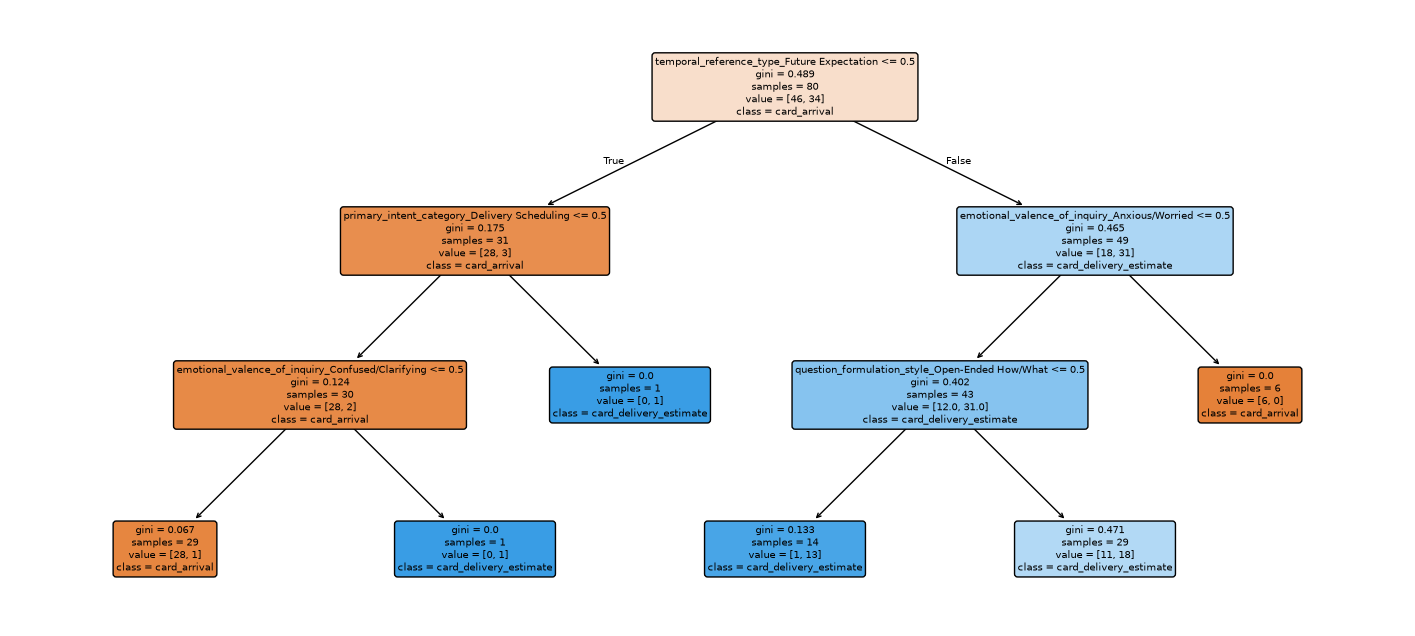

In [8]:
from sklearn.tree import export_text, plot_tree
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "feature": train_X.columns,
    "importance": tree.feature_importances_,
}).sort_values("importance", ascending=False)

display(importance_df[importance_df["importance"] > 0])
print(export_text(tree, feature_names=list(train_X.columns)))

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=list(train_X.columns), class_names=sorted(y_train.unique()), filled=True, rounded=True)
plt.show()


## Next Steps

This notebook is the generic walkthrough. If you're doing this as a course assignment, see the separate setup/assignment document you were given for exact submission requirements and provider credentials.